# Customers Like You: Analysis

In [1]:
import os, sys, json
os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None
sys.path.insert(0,'src')
import pandas as pd
from IPython.display import Image, Markdown, display

## DE1 to DE6: profile, clean, split, matrix

In [2]:
!python src/build_matrix.py
display(pd.read_csv('outputs/de1_data_profile.csv'))
display(pd.read_csv('outputs/de2_cleaning_log.csv'))

[DE1] Using cached raw data: data/interim/raw_combined.pkl

=== DE1 DATA PROFILE ===
                      dtype  n_missing  pct_missing  n_unique
column                                                       
Invoice              object          0         0.00     53628
StockCode            object          0         0.00      5305
Description          object       4382         0.41      5698
Quantity              int64          0         0.00      1057
InvoiceDate  datetime64[us]          0         0.00     47635
Price               float64          0         0.00      2807
Customer ID         float64     243007        22.77      5942
Country                 str          0         0.00        43
sheet                   str          0         0.00         2

--- Rows per sheet ---
                   rows          first_date           last_date
sheet                                                          
Year 2009-2010   525461 2009-12-01 07:45:00 2010-12-09 20:01:00
Year 2010-2011   

,column,dtype,n_missing,pct_missing,n_unique
0,Invoice,object,0,0.00,53628
1,StockCode,object,0,0.00,5305
2,Description,object,4382,0.41,5698
3,Quantity,int64,0,0.00,1057
4,InvoiceDate,datetime64[us],0,0.00,47635
5,Price,float64,0,0.00,2807
6,Customer ID,float64,243007,22.77,5942
7,Country,str,0,0.00,43
8,sheet,str,0,0.00,2


,rule,rows_removed,rows_remaining,reason,pct_of_raw_removed
0,Raw data (start),0,1067371,NaN,0.00
1,1. Cancellation invoices (Invoice starts with ...,19494,1047877,A cancelled order is not a purchase.,1.83
2,2. Quantity <= 0,3457,1044420,Returns/adjustments are not purchases.,0.32
3,3. Price <= 0,2750,1041670,Zero/negative price lines are not real sales.,0.26
4,4. Non-product StockCode (not 5 digits + optio...,4793,1036877,"POST, M, D, DOT, BANK CHARGES, gift vouchers e...",0.45
5,5. Missing Customer ID,234245,802632,No customer row to put the purchase in (~1/5 o...,21.95
6,"(info) Exact duplicate lines, NOT removed",0,802632,"11,930 duplicates kept; they add quantity, not...",0.00


In [3]:
for f in ['de3_split_report','de5_matrix_report']:
    display(Markdown(open(f'outputs/{f}.md').read()))

### DE3 split and hold-out report

| Item | Value |
|---|---:|
| cutoff_date | 2011-10-09 |
| train_lines | 683,670 |
| products_before_filter | 4,529 |
| products_after_filter | 3,686 |
| min_customers | 10 |
| purchase_value | log |
| test_lines | 118,962 |
| test_unique_customer_product_pairs | 95,278 |
| dropped_customer_not_in_train | 13,840 |
| dropped_product_not_in_train_catalogue | 4,762 |
| dropped_already_bought_in_train | 31,754 |
| heldout_pairs | 44,922 |
| test_customers_evaluated | 1,913 |
| test_customers_total | 2,423 |


### DE5 matrix report

| Item | Value |
|---|---:|
| n_customers | 5,471 |
| n_products | 3,686 |
| non_zeros | 413,691 |
| sparsity_pct | 97.95 |
| avg_products_per_customer | 75.6 |
| dense_memory_MB | 161.3 |
| sparse_memory_MB | 4.99 |
| dense_over_sparse | 32.4 |
| k50_factors_MB | 3.66 |


## ML1 to ML7: model, evaluation, comparison, segments

[ML2] k=  10 err=0.876 val_hit=0.269 fit=0.1s
[ML2] k=  20 err=0.846 val_hit=0.395 fit=0.1s
[ML2] k=  50 err=0.790 val_hit=0.509 fit=0.2s
[ML2] k= 100 err=0.727 val_hit=0.539 fit=0.5s
[ML2] k= 200 err=0.639 val_hit=0.590 fit=0.8s
[ML2] k= 300 err=0.571 val_hit=0.605 fit=1.2s
[ML2] k= 500 err=0.466 val_hit=0.598 fit=2.3s
                                                        Measure                                                                                                                                                                                                                                                                                                                PCA                                                                                                                                Truncated SVD
                                                         k used                                                                                                       

# ML1 Decision note
**Main model: Truncated SVD.  Comparison model: PCA (ML5).**
- The purchase matrix is large and sparse. Truncated SVD works on it directly;
  PCA centres the columns, which turns the zeros into small negative numbers and
  makes the matrix dense (or forces special solvers).
- A recommender needs customer factors AND product factors from one fit. SVD
  gives both (U S and V).
- Without centring, SVD describes what customers actually bought. PCA describes
  how they differ from the average customer, which is not the same question as
  "what do customers like you also buy".
- Hypothesis to test in ML5: both methods give similar hit rates, but SVD is
  faster / lighter, and PCA's first component is more interpretable.

Author: Kwadwo Osafo


,k,rel_recon_error,energy_kept,val_hit_rate_at_10,val_baseline_hit_rate,fit_seconds
0,10,0.8761,0.2324,0.2686,0.3467,0.08
1,20,0.8459,0.2845,0.3947,0.3467,0.10
2,50,0.7895,0.3767,0.5085,0.3467,0.22
3,100,0.7274,0.4709,0.5387,0.3467,0.46
4,200,0.6388,0.5919,0.5898,0.3467,0.84
5,300,0.5708,0.6741,0.6053,0.3467,1.24
6,500,0.4662,0.7827,0.5983,0.3467,2.32


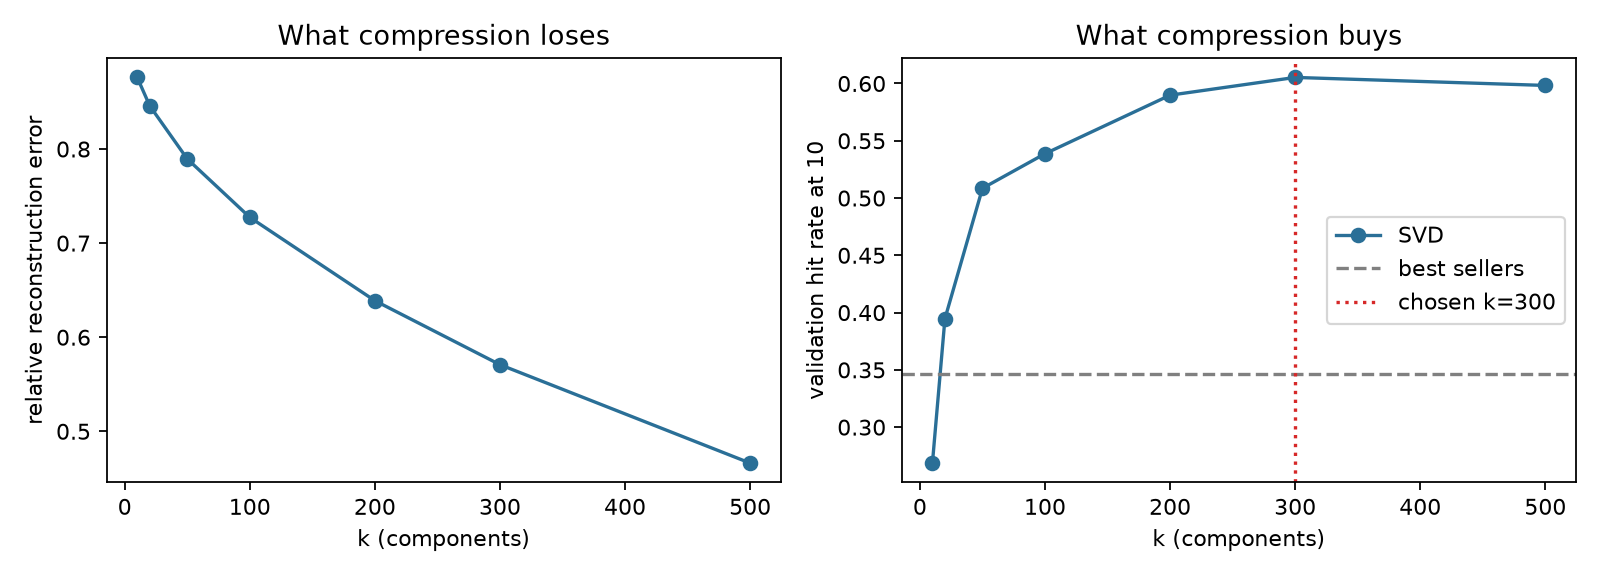

In [4]:
!python src/ml_analysis.py
display(Markdown(open('outputs/ml1_decision_note.md').read()))
display(pd.read_csv('outputs/ml2_k_sweep.csv'))
display(Image('outputs/fig_ml2_k_sweep.png'))

In [5]:
display(Markdown(open('outputs/ml5_comparison_table.md').read()))
display(pd.read_csv('outputs/ml4_results.csv'))
display(pd.read_csv('outputs/ml7_sensitivity.csv'))

| Measure | PCA | Truncated SVD |
|---|---|---|
| k used | 300 | 300 |
| Fit time (seconds) | 1.09 | 2.57 |
| Peak memory during fit (MB) | 35.7 | 42.5 |
| Size of stored factors (MB) | 22.01 | 21.98 |
| Variance explained / relative reconstruction error | 66.1% variance explained; rel. error 0.570 | rel. error 0.571 (67.4% of energy kept) |
| Hit rate at 10 on held-out purchases | 20.7% | 21.1% |
| Best-seller baseline hit rate at 10 | 27.0% | 27.0% |
| What component 1 represents (auto-draft: rewrite in your words) | Main way customers differ from the average customer. Pushes up: PACK OF 72 RETROSPOT CAKE CASE; JUMBO BAG RED RETROSPOT; LUNCH BAG RED RETROSPOT; WHITE HANGING HEART T-LIGHT HO. Pushes down: AMBER GLASS TASSLE BAG CHARM; PURPLE GLASS TASSLE BAG CHARM; BROWN ANTIQUE CUBE CANDLE; WHITE HYDRANGEA ART FLOWER. | Overall purchase volume: 100% of products load with the same sign; score tracks number of products bought (r=0.89) and total value (r=0.97). |


,model,hit_rate_at_10
0,Truncated SVD,0.2107
1,PCA,0.2070
2,Best sellers,0.2703


,purchase_value,hit_rate_at_10,baseline_hit_rate
0,log,0.2107,0.2703
1,binary,0.2248,0.2703
2,count,0.1312,0.2703


,segment,name,draft_name,customers,share_pct,median_products_bought,median_total_value,top_countries,top_products
0,0,Light UK buyers: Feng Shui Pillar Candle fans,Light UK buyers: Feng Shui Pillar Candle fans,2022,37.0,20.0,39.56,"United Kingdom 94%, Germany 1%, France 1%",FENG SHUI PILLAR CANDLE | SET OF 3 COLOURED F...
1,1,Heavy mostly-UK buyers: Pack Of 72 Retrospot C...,Heavy mostly-UK buyers: Pack Of 72 Retrospot C...,679,12.4,60.0,136.12,"United Kingdom 84%, Germany 3%, France 3%",PACK OF 72 RETROSPOT CAKE CASE | 60 TEATIME FA...
2,2,Heavy mostly-UK buyers: Mini Paint Set Vintage...,Heavy mostly-UK buyers: Mini Paint Set Vintage...,970,17.7,67.5,139.11,"United Kingdom 86%, Germany 3%, France 3%",MINI PAINT SET VINTAGE | VINTAGE SNAP CARDS |...
3,3,Heavy UK buyers: White Hanging Heart T-Light ...,Heavy UK buyers: White Hanging Heart T-Light ...,1153,21.1,54.0,103.66,"United Kingdom 97%, Cyprus 0%, Spain 0%",WHITE HANGING HEART T-LIGHT HO | ASSORTED COLO...
4,4,Heavy mostly-UK buyers: Jumbo Bag Red Retrospo...,Heavy mostly-UK buyers: Jumbo Bag Red Retrospo...,647,11.8,81.0,181.85,"United Kingdom 88%, Germany 3%, France 3%",JUMBO BAG RED RETROSPOT | LUNCH BAG RED RETROS...


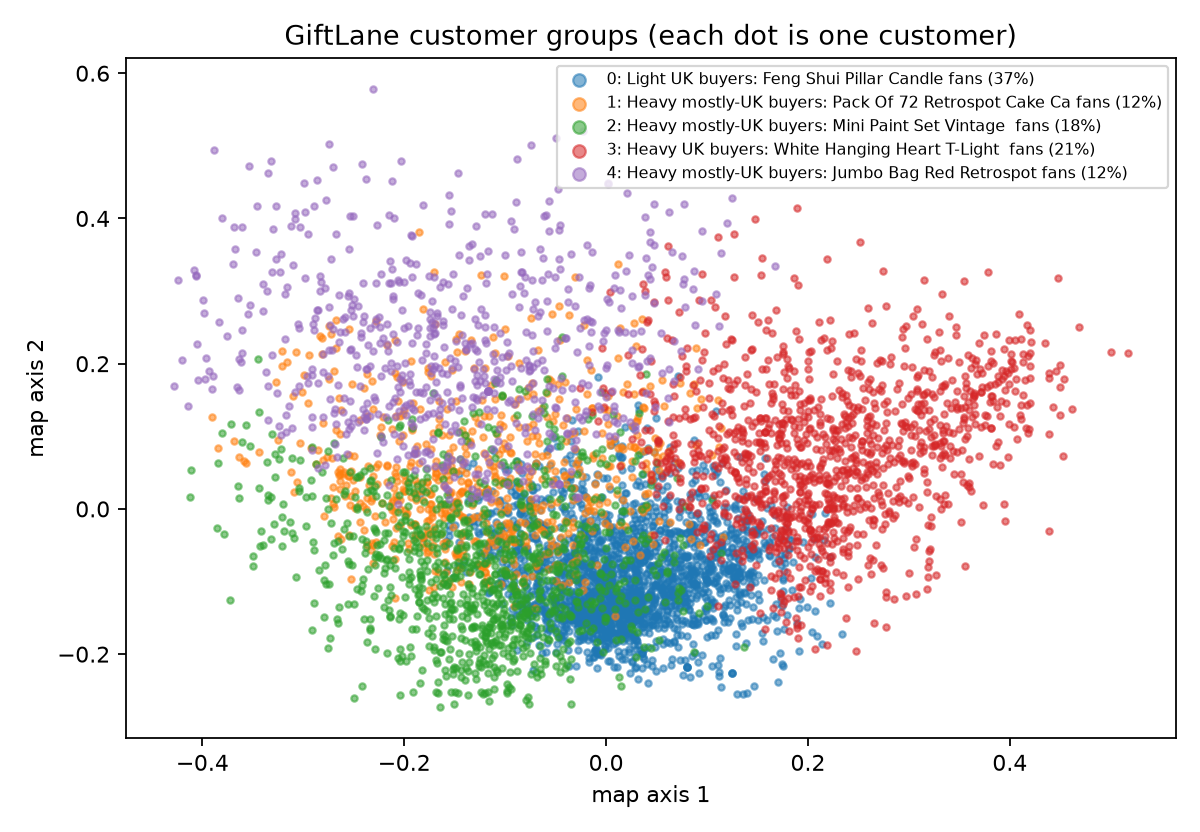

,product,rank,also_bought
0,WHITE HANGING HEART T-LIGHT HOLDER,1,CANDLEHOLDER PINK HANGING HEART
1,WHITE HANGING HEART T-LIGHT HOLDER,2,"WHITE PEARL BEADED HEART, SMALL"
2,WHITE HANGING HEART T-LIGHT HOLDER,3,RED HANGING HEART T-LIGHT HOLDER
3,WHITE HANGING HEART T-LIGHT HOLDER,4,12 ASS ZINC CHRISTMAS DECORATIONS
4,WHITE HANGING HEART T-LIGHT HOLDER,5,WHITE HYDRANGEA ART FLOWER
5,WHITE HANGING HEART T-LIGHT HOLDER,6,HANGING METAL BIRD BATH
6,WHITE HANGING HEART T-LIGHT HOLDER,7,JAZZ HEARTS SPIRAL NOTEPAD
7,WHITE HANGING HEART T-LIGHT HOLDER,8,RED HANGING METAL STAR TLIGHT HLDR
8,WHITE HANGING HEART T-LIGHT HOLDER,9,BUTTONS DESIGN JEWELLERY BOX
9,WHITE HANGING HEART T-LIGHT HOLDER,10,LADS ONLY TISSUE BOX


In [6]:
display(pd.read_csv('outputs/ml6_segments.csv'))
display(Image('outputs/fig_ml6_customer_map.png'))
display(pd.read_csv('outputs/ml3_similar_products_examples.csv').head(20))